In [10]:
import pandas as pd 
from statsforecast import StatsForecast

from statsforecast.models import (
    AutoARIMA,
    MSTL,
    SeasonalNaive,
    AutoTheta,
    HoltWinters,
    HistoricAverage,
)

import matplotlib.pyplot as plt
from utilsforecast.evaluation import evaluate
from utilsforecast.losses import mse 

In [11]:
#importing and reading the ambulance response data
df = pd.read_csv("data/Daily_Responses_5_Years_2019_full.csv")
df.head()

,ds,y,area
0,2013-12-30,220,Cornwall
1,2013-12-30,129,Gloucestershire
2,2013-12-30,255,Wiltshire
3,2013-12-30,2042,Trust
4,2013-12-30,336,Dorset


In [12]:
#renaming area column to allow forecasting to work
df_rename = df.rename(columns={'area':'unique_id'}).copy()
df_rename.head()
#filtering to Trust area
Trust = df_rename[df_rename["unique_id"]=="Trust"]


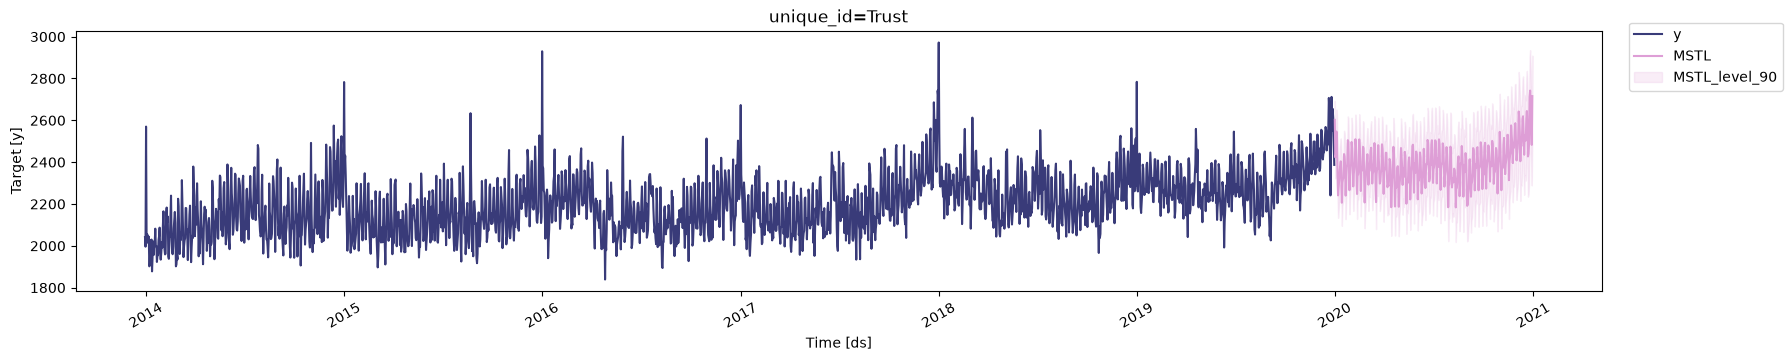

In [13]:
# making the fitted model
models = [MSTL(
    season_length=[7,365],
    trend_forecaster=AutoARIMA()
)]

sf = StatsForecast(
    models=models,
    freq='D'
)
sf.fit(df=Trust)

# making the predicted model
forecast_df = sf.predict(
    h=365, level=[90]
)
forecast_df.tail()

# plot the forecast
sf.plot(Trust,forecast_df, level=[90])


In [66]:
# training the model for many series 
# list of models 

models = [
    SeasonalNaive(season_length=365),
    AutoTheta(season_length=365),
    HoltWinters(season_length=365),
    HistoricAverage(),
    MSTL(season_length=[7,365]),
]

sf = StatsForecast(
    models=models,
    freq='D',
    fallback_model=SeasonalNaive(season_length=365),
    n_jobs=-1
)

forecasts_df = sf.forecast(df=Trust, h=365, level=[90])
forecasts_df.head()



,unique_id,ds,SeasonalNaive,SeasonalNaive-lo-90,SeasonalNaive-hi-90,AutoTheta,AutoTheta-lo-90,AutoTheta-hi-90,HoltWinters,HoltWinters-lo-90,HoltWinters-hi-90,HistoricAverage,HistoricAverage-lo-90,HistoricAverage-hi-90,MSTL,MSTL-lo-90,MSTL-hi-90
0,Trust,2020-01-01,2784.0,2545.828613,3022.171387,2400.841064,2212.358154,2602.158203,2744.033936,2540.203857,2947.864014,2202.15332,1969.71106,2434.595459,2617.112305,2519.970215,2714.254150
1,Trust,2020-01-02,2277.0,2038.828491,2515.171387,2179.419922,1943.706665,2391.914307,2505.258789,2301.428955,2709.088867,2202.15332,1969.71106,2434.595459,2415.005127,2313.252441,2516.758057
2,Trust,2020-01-03,2260.0,2021.828491,2498.171387,2085.447998,1756.883667,2404.204102,2405.708984,2201.878662,2609.539062,2202.15332,1969.71106,2434.595459,2393.959717,2287.796143,2500.123291
3,Trust,2020-01-04,2349.0,2110.828613,2587.171387,2062.531250,1685.715576,2392.129639,2383.062988,2179.232666,2586.893066,2202.15332,1969.71106,2434.595459,2503.865479,2393.467285,2614.263916
4,Trust,2020-01-05,2369.0,2130.828613,2607.171387,2011.649536,1617.510864,2395.007812,2332.797852,2128.967529,2536.628418,2202.15332,1969.71106,2434.595459,2438.401855,2323.925293,2552.878174


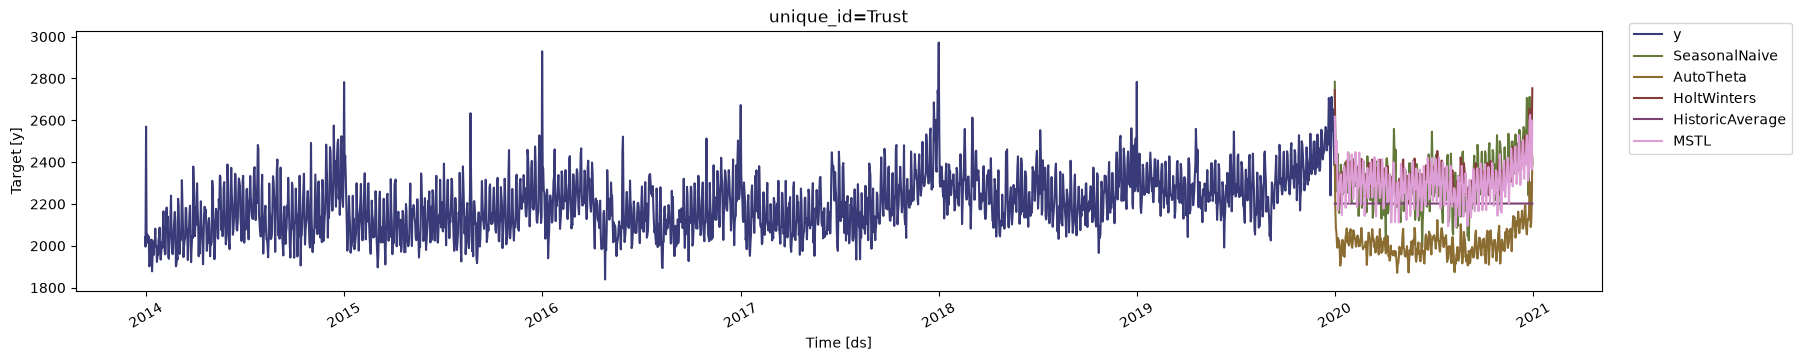

In [15]:
sf.plot(Trust,forecasts_df)

In [16]:
#cross validating the models
cv_df = sf.cross_validation(
    df = Trust,
    h=365, #forecasts 365 days ahead
    step_size=182, #moves the window 182 days ahead before each forecast
    n_windows=5, #evaluates 7 windows
)

cv_df.head()

,unique_id,ds,cutoff,y,SeasonalNaive,AutoTheta,HoltWinters,HistoricAverage,MSTL
0,Trust,2017-01-03,2017-01-02,2280.0,2265.0,2350.972412,2287.020996,2151.933594,2152.381592
1,Trust,2017-01-04,2017-01-02,2220.0,2254.0,2351.048584,2223.115967,2151.933594,2118.221436
2,Trust,2017-01-05,2017-01-02,2128.0,2134.0,2351.125000,2116.107178,2151.933594,2151.009766
3,Trust,2017-01-06,2017-01-02,2114.0,2034.0,2351.201172,1997.861572,2151.933594,2082.406494
4,Trust,2017-01-07,2017-01-02,2303.0,2160.0,2351.277588,2087.608154,2151.933594,2160.003906


In [17]:
# scoring each models evaluation 
def evaluate_cv(Trust, metric):
    models = Trust.columns.drop(['unique_id', 'ds', 'y', 'cutoff']).tolist()
    evals = evaluate(Trust, metrics=[metric], models=models)
    evals = evals.drop(columns=['metric'])
    evals['best_model'] = evals[models].idxmin(axis=1)
    return evals

# create a dataframe with the evaluation of cross-validation using a MSE metric
evaluation_df = evaluate_cv(cv_df, mse)
evaluation_df.head() 


,unique_id,cutoff,SeasonalNaive,AutoTheta,HoltWinters,HistoricAverage,MSTL,best_model
0,Trust,2017-01-02,23117.212891,47185.921875,26636.789062,22753.558594,11296.505859,MSTL
1,Trust,2017-07-03,27255.478516,22169.806641,28501.097656,28340.511719,13777.846680,MSTL
2,Trust,2018-01-01,24237.630859,35851.910156,20418.470703,21301.275391,31904.238281,HoltWinters
3,Trust,2018-07-02,17874.210938,25754.205078,20126.935547,19520.003906,10691.775391,MSTL
4,Trust,2018-12-31,20934.613281,203252.234375,24660.210938,30851.617188,47829.656250,SeasonalNaive


In [18]:
# creating a summary table for my evaluation 
evaluation_df['best_model'].value_counts().to_frame().reset_index()

,best_model,count
0,MSTL,3
1,HoltWinters,1
2,SeasonalNaive,1


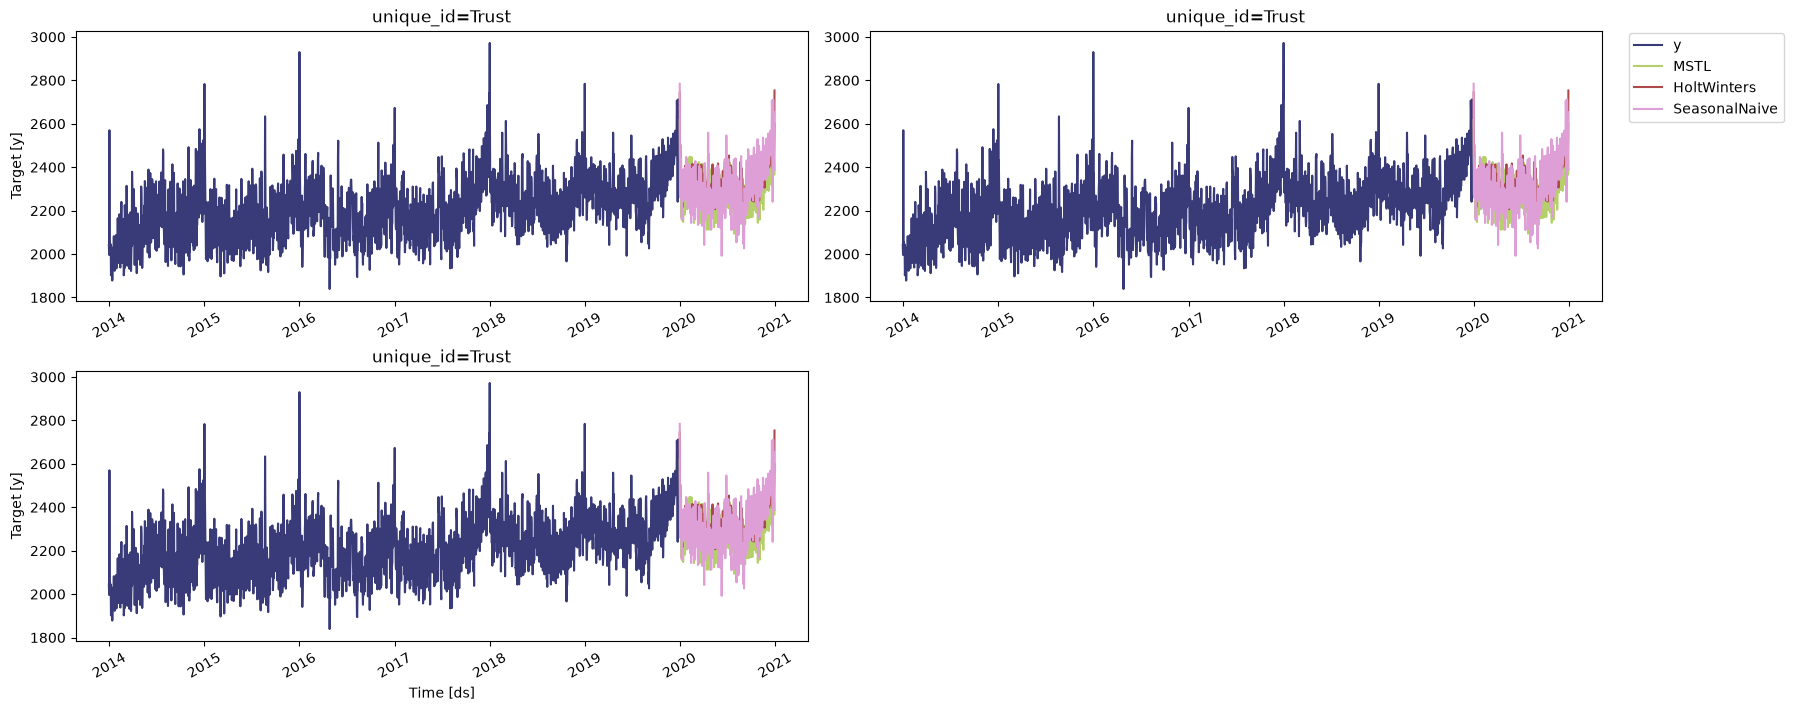

In [19]:
#plotting the unique_ids where a specific model wins
seasonal_ids = evaluation_df.query('best_model=="MSTL"')['unique_id']
sf.plot(Trust,forecasts_df,unique_ids=seasonal_ids, models=["MSTL","HoltWinters","SeasonalNaive"])

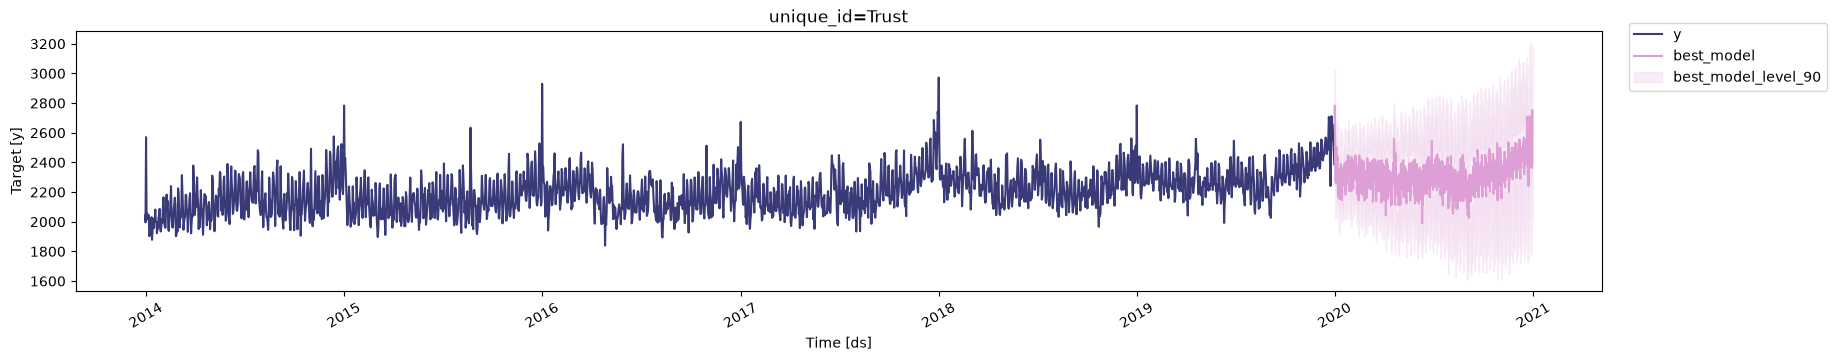

In [20]:
#making a dataframe with the best possible forecast for each unique_id
def get_best_model_forecast(forecasts_df,evaluation_df):
    with_best=forecasts_df.merge(evaluation_df[['unique_id','best_model']])
    res = with_best[['unique_id','ds']].copy()
    for suffix in ('', '-lo-90','-hi-90'):
        res[f'best_model{suffix}'] = with_best.apply(lambda row: row[row['best_model'] + suffix],axis=1)
    return res

prod_forecasts_df = get_best_model_forecast(forecasts_df,evaluation_df)
prod_forecasts_df.head()

sf.plot(Trust, prod_forecasts_df, level=[90])

# All areas included

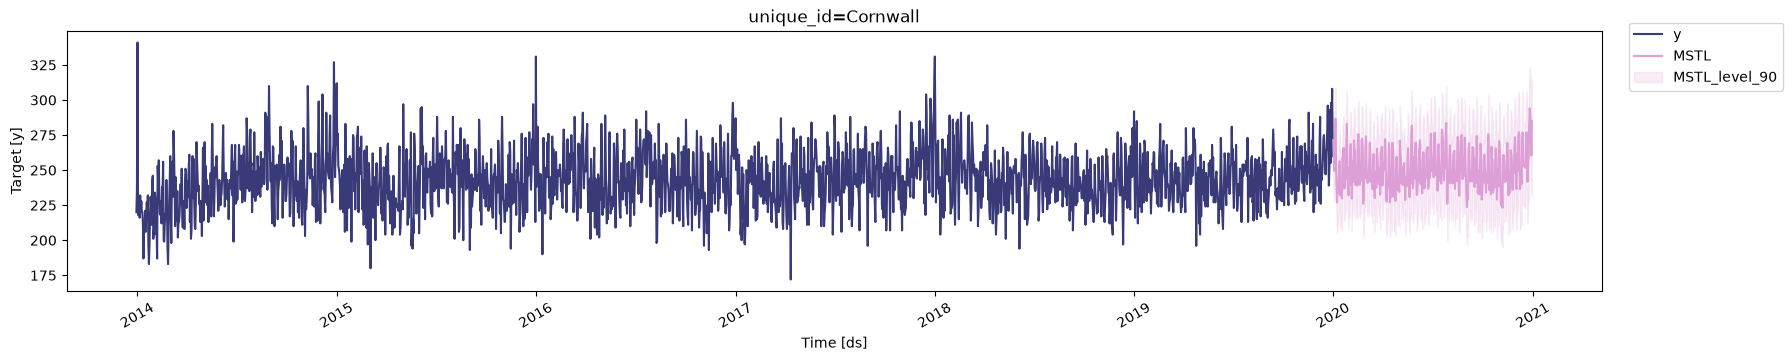

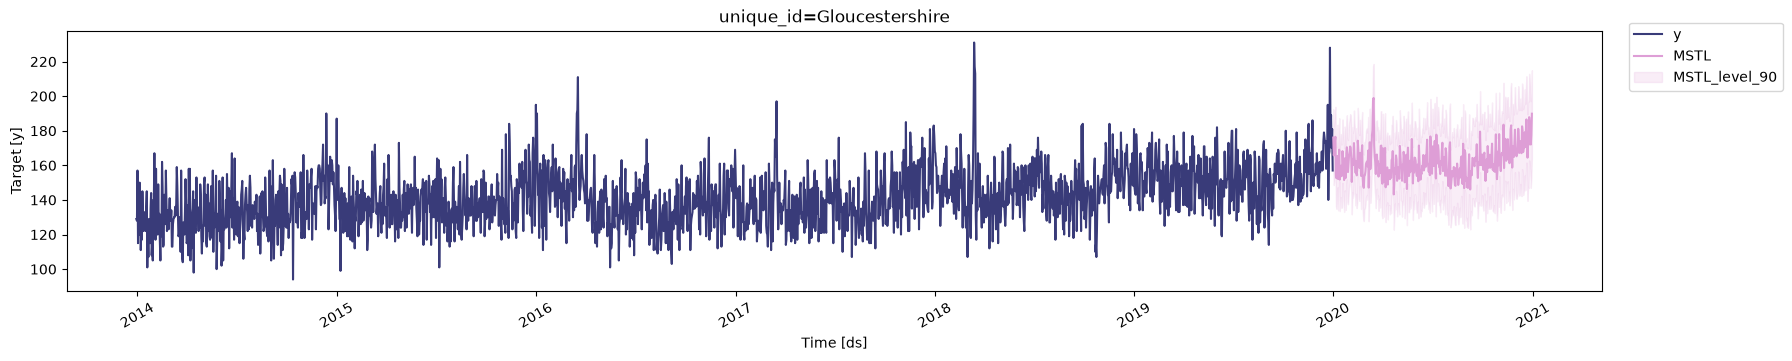

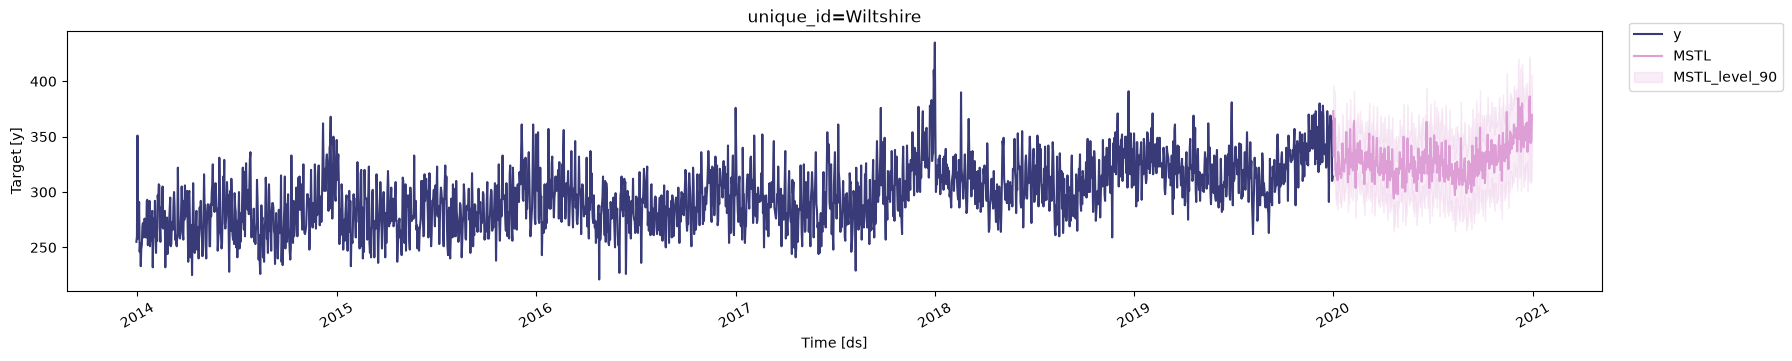

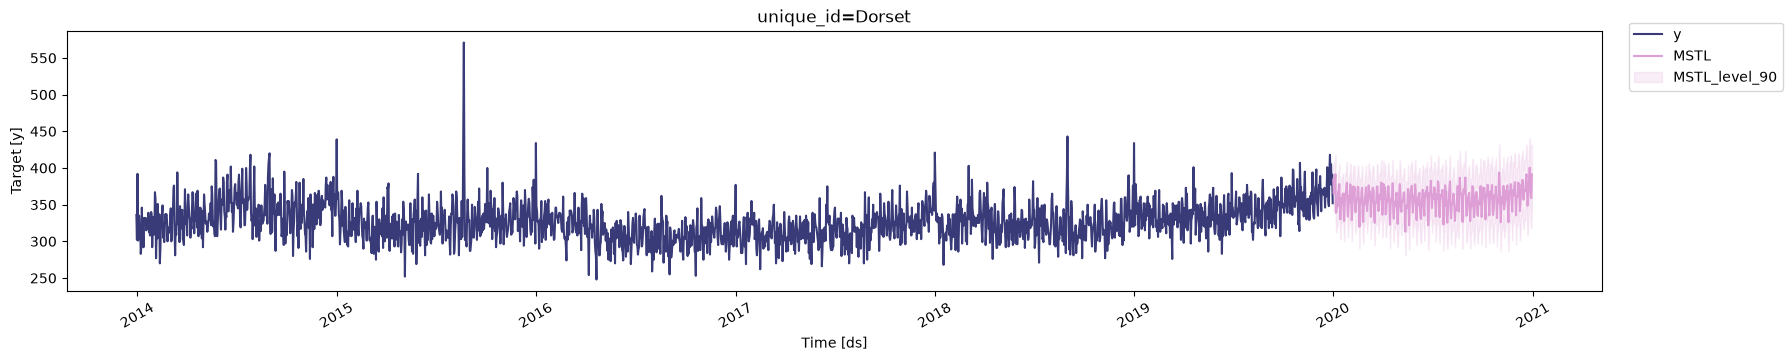

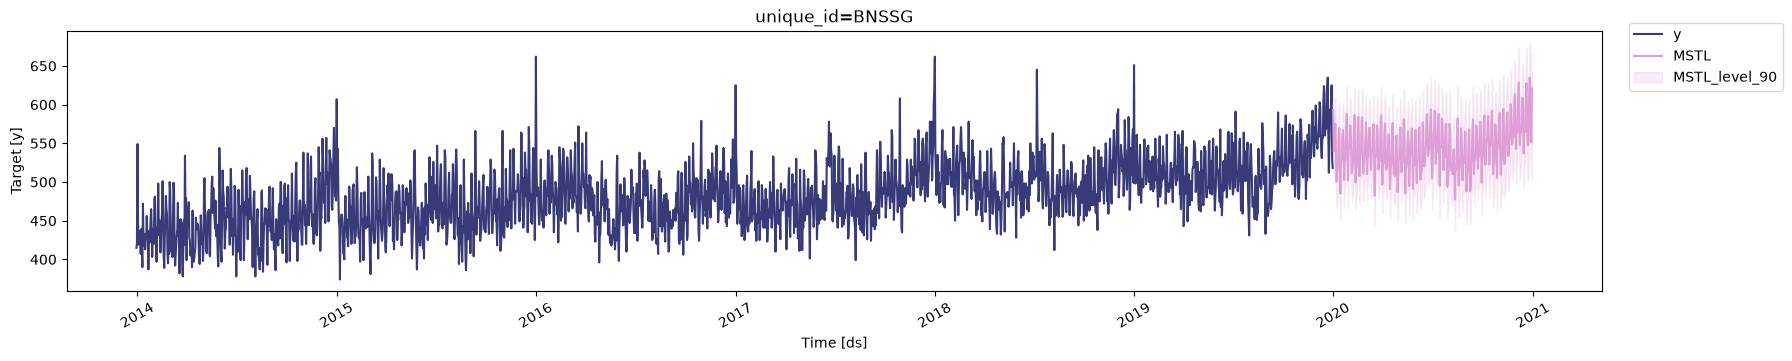

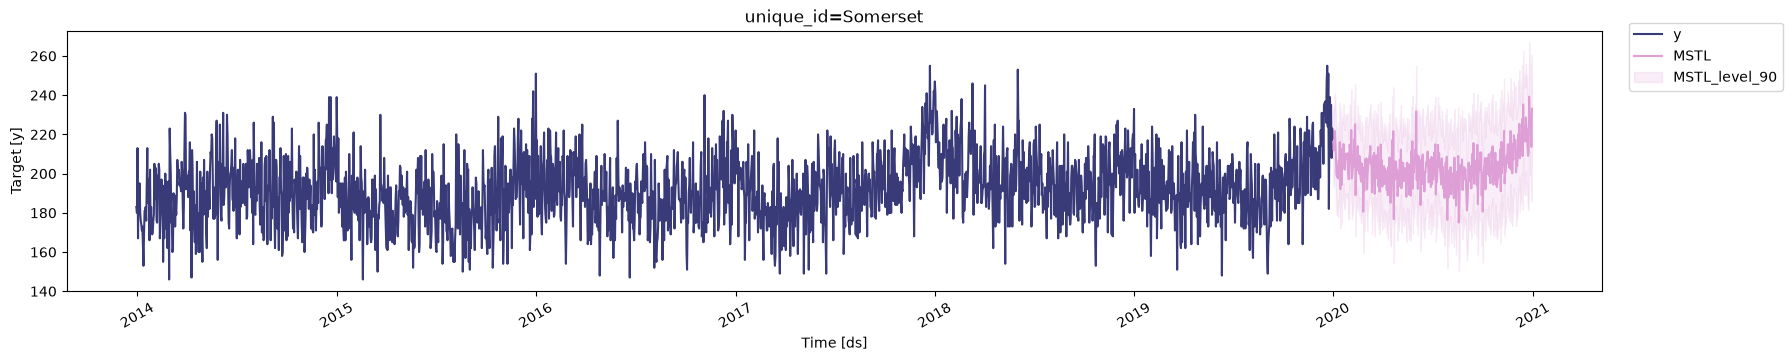

In [21]:
#need to loop through the other areas - make a dictionary for each area
areas = ['Cornwall','Gloucestershire','Wiltshire','Dorset','BNSSG','Somerset']

for area_name in areas :
    area_data = df_rename[df_rename['unique_id']==area_name]
    models = [MSTL(
        season_length=[7,365],
        trend_forecaster=AutoARIMA()
        )]
    sf = StatsForecast(
        models=models,
        freq='D'
    )
    sf.fit(df=area_data)
    forecast_df = sf.predict(
        h=365, level=[90]
    )
    forecast_df.tail()
    fig = sf.plot(area_data,forecast_df,level=[90])

    display(fig)
    



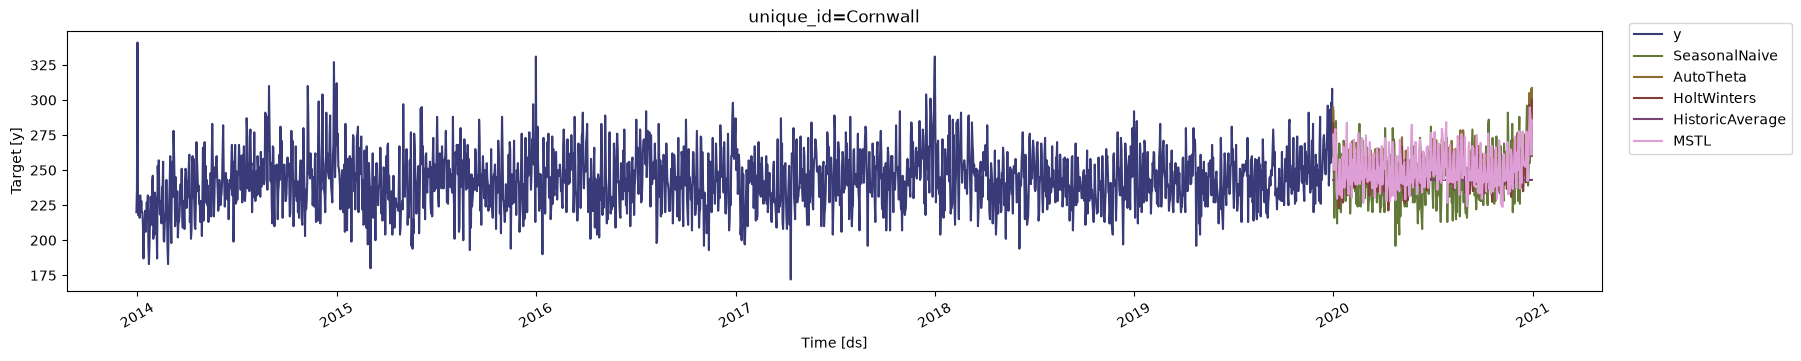

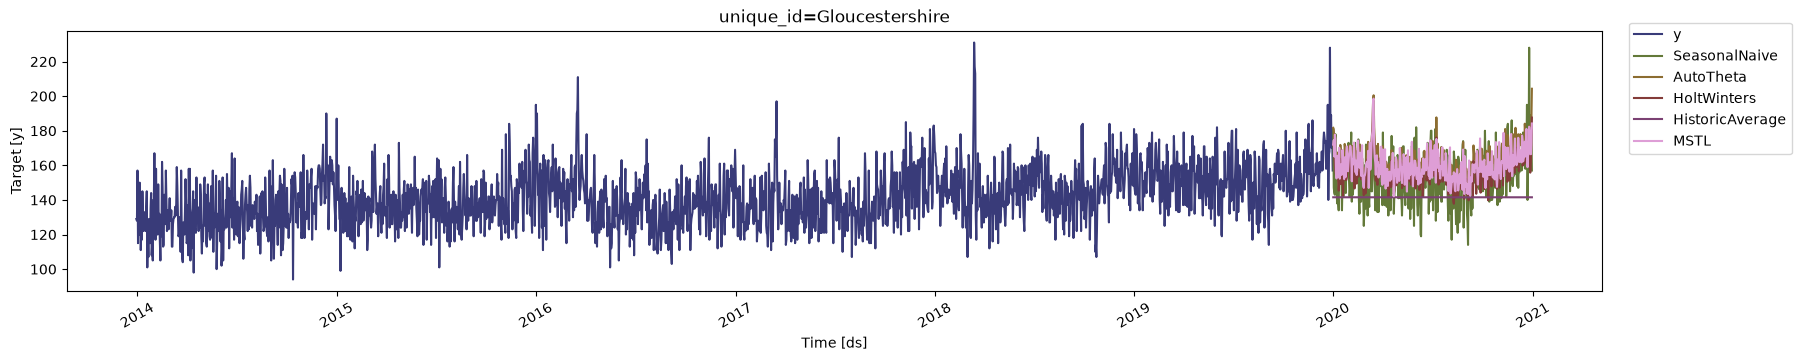

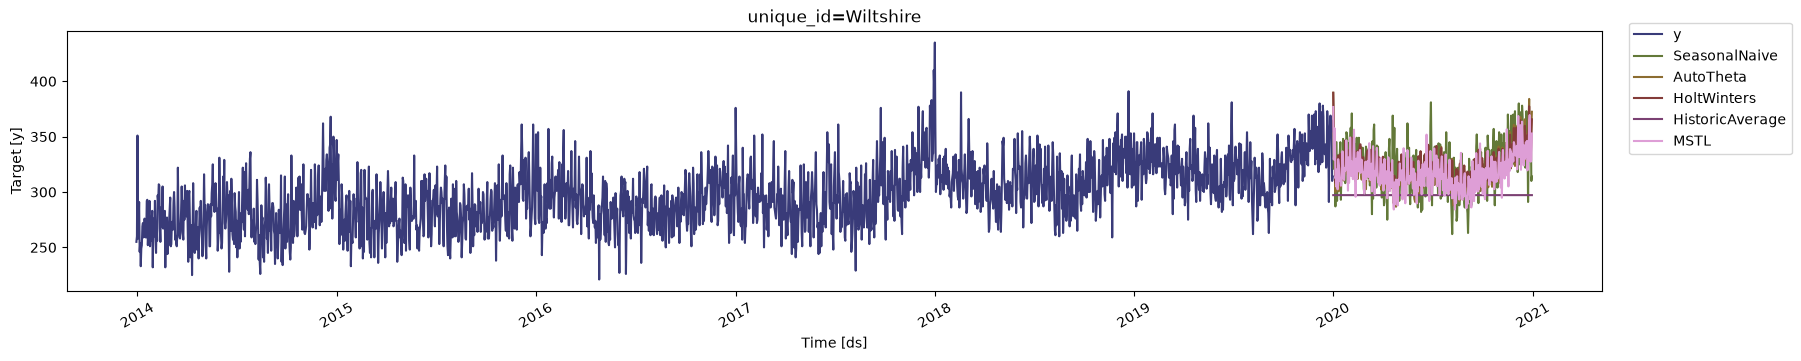

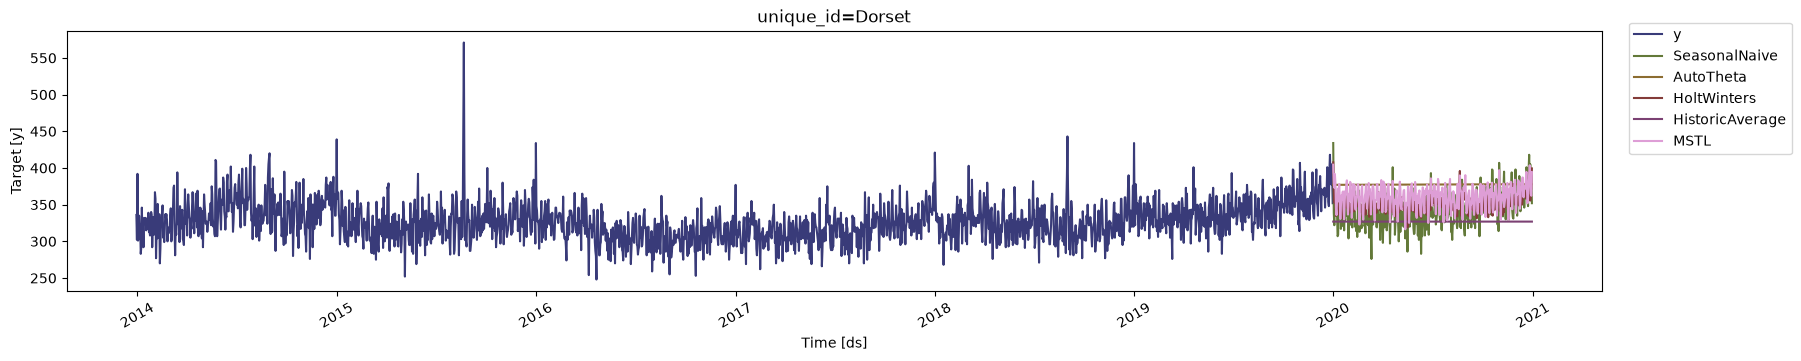

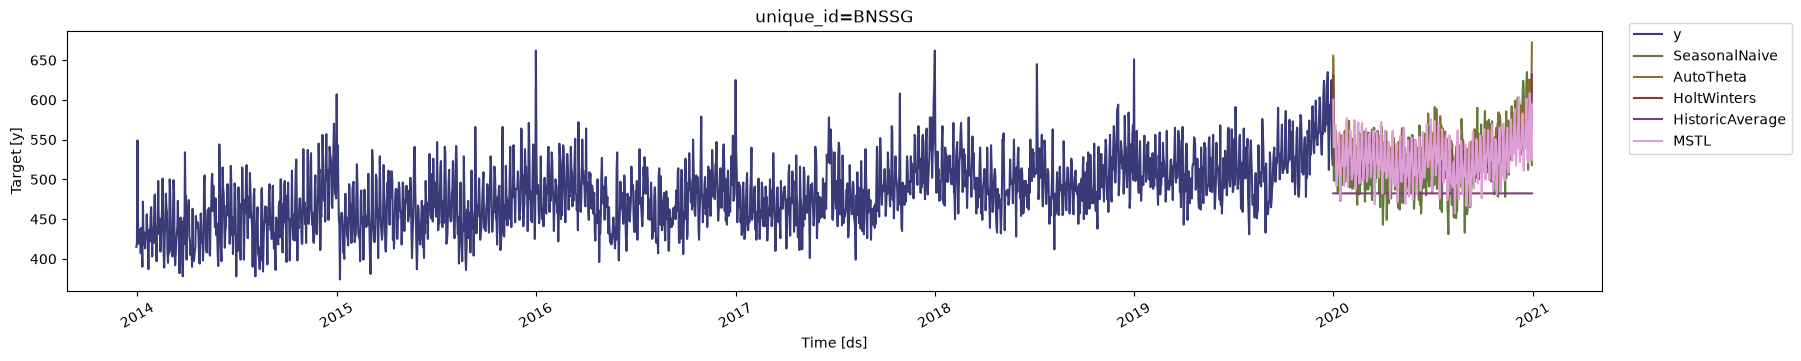

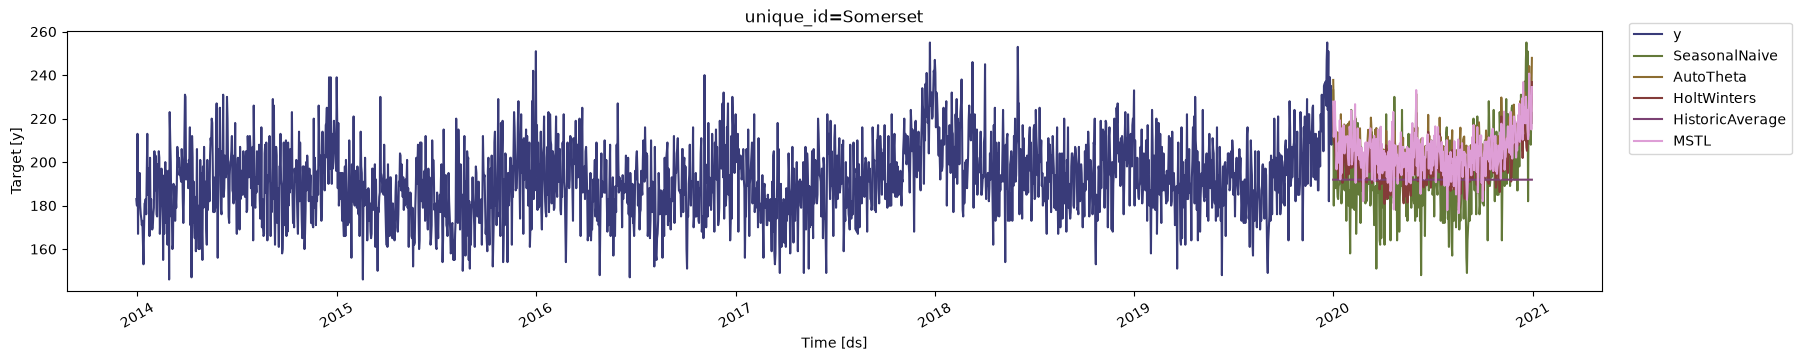

In [34]:
# training the model for many series 
for area_name in areas :
    area_data = df_rename[df_rename['unique_id']==area_name]
    models = [
        SeasonalNaive(season_length=365),
        AutoTheta(season_length=365),
        HoltWinters(season_length=365),
        HistoricAverage(),
        MSTL(season_length=[7,365]),
        ]
    sf = StatsForecast(
        models=models,
        freq='D',
        fallback_model=SeasonalNaive(season_length=365),
        n_jobs=-1
        )
    forecasts_df = sf.forecast(df=area_data, h=365, level=[90])
    forecasts_df.head()

    fig2 = sf.plot(area_data,forecasts_df)
    display(fig2)
   



# Redoing it for all areas

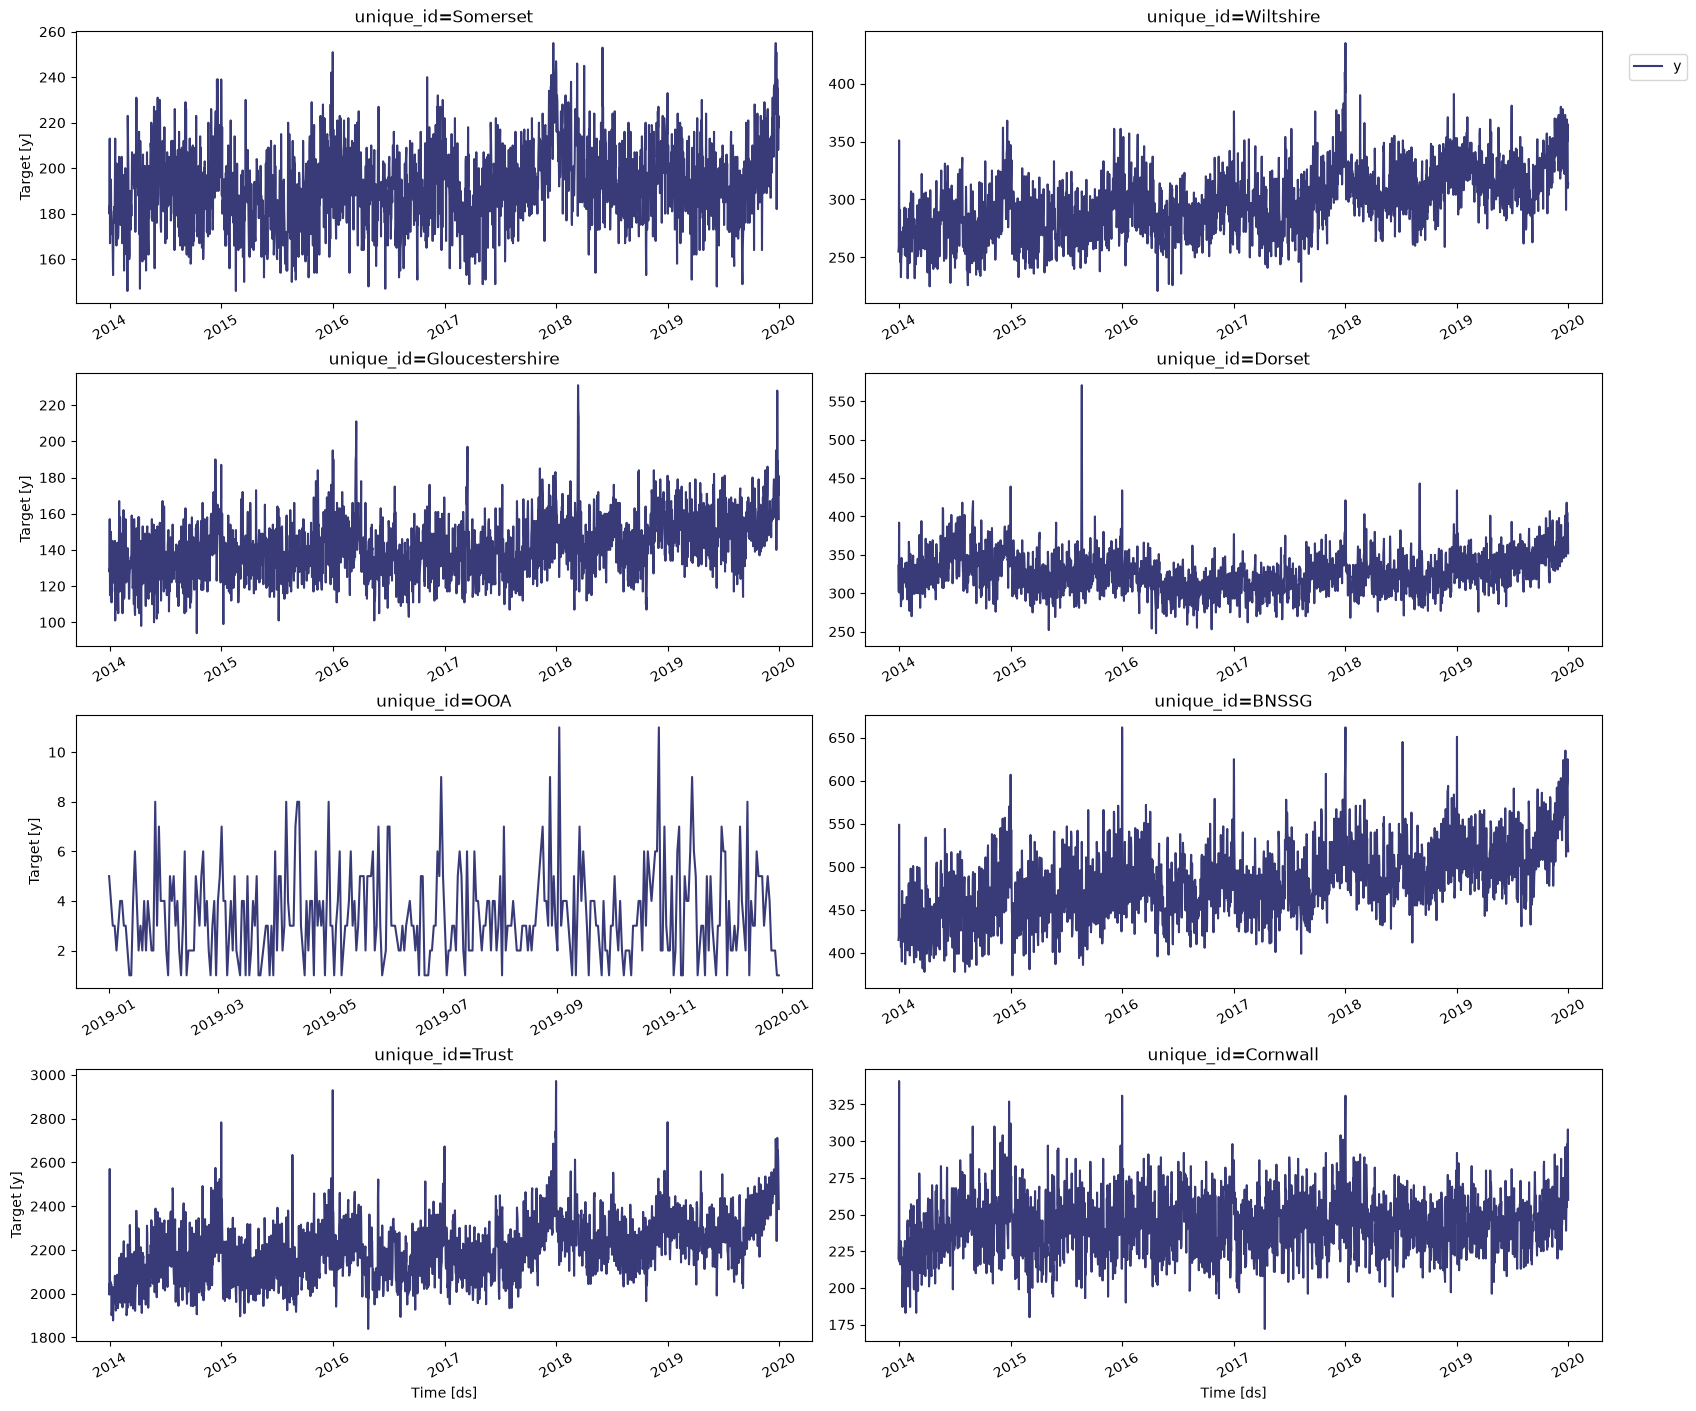

In [ ]:
# exploring all of the data
StatsForecast.plot(df_rename)

In [70]:
# training the model for many series 
# list of models 

df_filtered = df_rename[df_rename['unique_id'] != 'OOA']

models = [
    SeasonalNaive(season_length=365),
    AutoTheta(season_length=365),
    HoltWinters(season_length=365),
    HistoricAverage(),
    MSTL(season_length=[7,365]),
]

sf = StatsForecast(
    models=models,
    freq='D',
    fallback_model=SeasonalNaive(season_length=365),
    n_jobs=-1
)

forecasts_df = sf.forecast(df=df_filtered, h=365, level=[90])
display(forecasts_df.head())
display(forecasts_df.tail())



,unique_id,ds,SeasonalNaive,SeasonalNaive-lo-90,SeasonalNaive-hi-90,AutoTheta,AutoTheta-lo-90,AutoTheta-hi-90,HoltWinters,HoltWinters-lo-90,HoltWinters-hi-90,HistoricAverage,HistoricAverage-lo-90,HistoricAverage-hi-90,MSTL,MSTL-lo-90,MSTL-hi-90
0,BNSSG,2020-01-01,651.0,579.457886,722.542114,655.517456,599.079773,715.798096,631.052551,572.521667,689.583435,482.361603,412.197662,552.525513,600.432800,567.810242,633.055359
1,BNSSG,2020-01-02,499.0,427.457916,570.542114,576.731445,526.776733,630.973999,558.448914,499.917999,616.979797,482.361603,412.197662,552.525513,540.420105,507.244141,573.596069
2,BNSSG,2020-01-03,498.0,426.457916,569.542114,554.044006,500.588593,601.469543,540.205200,481.674316,598.736145,482.361603,412.197662,552.525513,543.363037,509.642731,577.083313
3,BNSSG,2020-01-04,527.0,455.457916,598.542114,531.570862,475.151306,580.132202,521.489197,462.958252,580.020142,482.361603,412.197662,552.525513,565.078796,530.822815,599.334778
4,BNSSG,2020-01-05,499.0,427.457916,570.542114,528.604431,478.032501,566.840332,518.939880,460.408905,577.470886,482.361603,412.197662,552.525513,569.052795,534.269348,603.836182


,unique_id,ds,SeasonalNaive,SeasonalNaive-lo-90,SeasonalNaive-hi-90,AutoTheta,AutoTheta-lo-90,AutoTheta-hi-90,HoltWinters,HoltWinters-lo-90,HoltWinters-hi-90,HistoricAverage,HistoricAverage-lo-90,HistoricAverage-hi-90,MSTL,MSTL-lo-90,MSTL-hi-90
2915,Wiltshire,2020-12-26,369.0,319.276642,418.723358,357.186127,281.859619,445.818115,354.524445,315.671204,393.377716,297.19516,249.8582,344.532104,369.536438,296.891174,442.181732
2916,Wiltshire,2020-12-27,350.0,300.276642,399.723358,330.667969,249.645721,404.606689,330.699097,291.844543,369.553619,297.19516,249.8582,344.532104,329.581421,256.847260,402.315613
2917,Wiltshire,2020-12-28,365.0,315.276642,414.723358,327.972534,245.724106,410.054474,329.150024,290.294189,368.005859,297.19516,249.8582,344.532104,327.397766,254.574799,400.220764
2918,Wiltshire,2020-12-29,310.0,260.276642,359.723358,358.679138,280.469421,436.489105,352.374634,313.517517,391.231750,297.19516,249.8582,344.532104,329.141418,256.229736,402.053070
2919,Wiltshire,2020-12-30,314.0,264.276642,363.723358,372.473450,278.727905,460.372650,365.643005,326.784607,404.501404,297.19516,249.8582,344.532104,352.825775,279.825531,425.826019


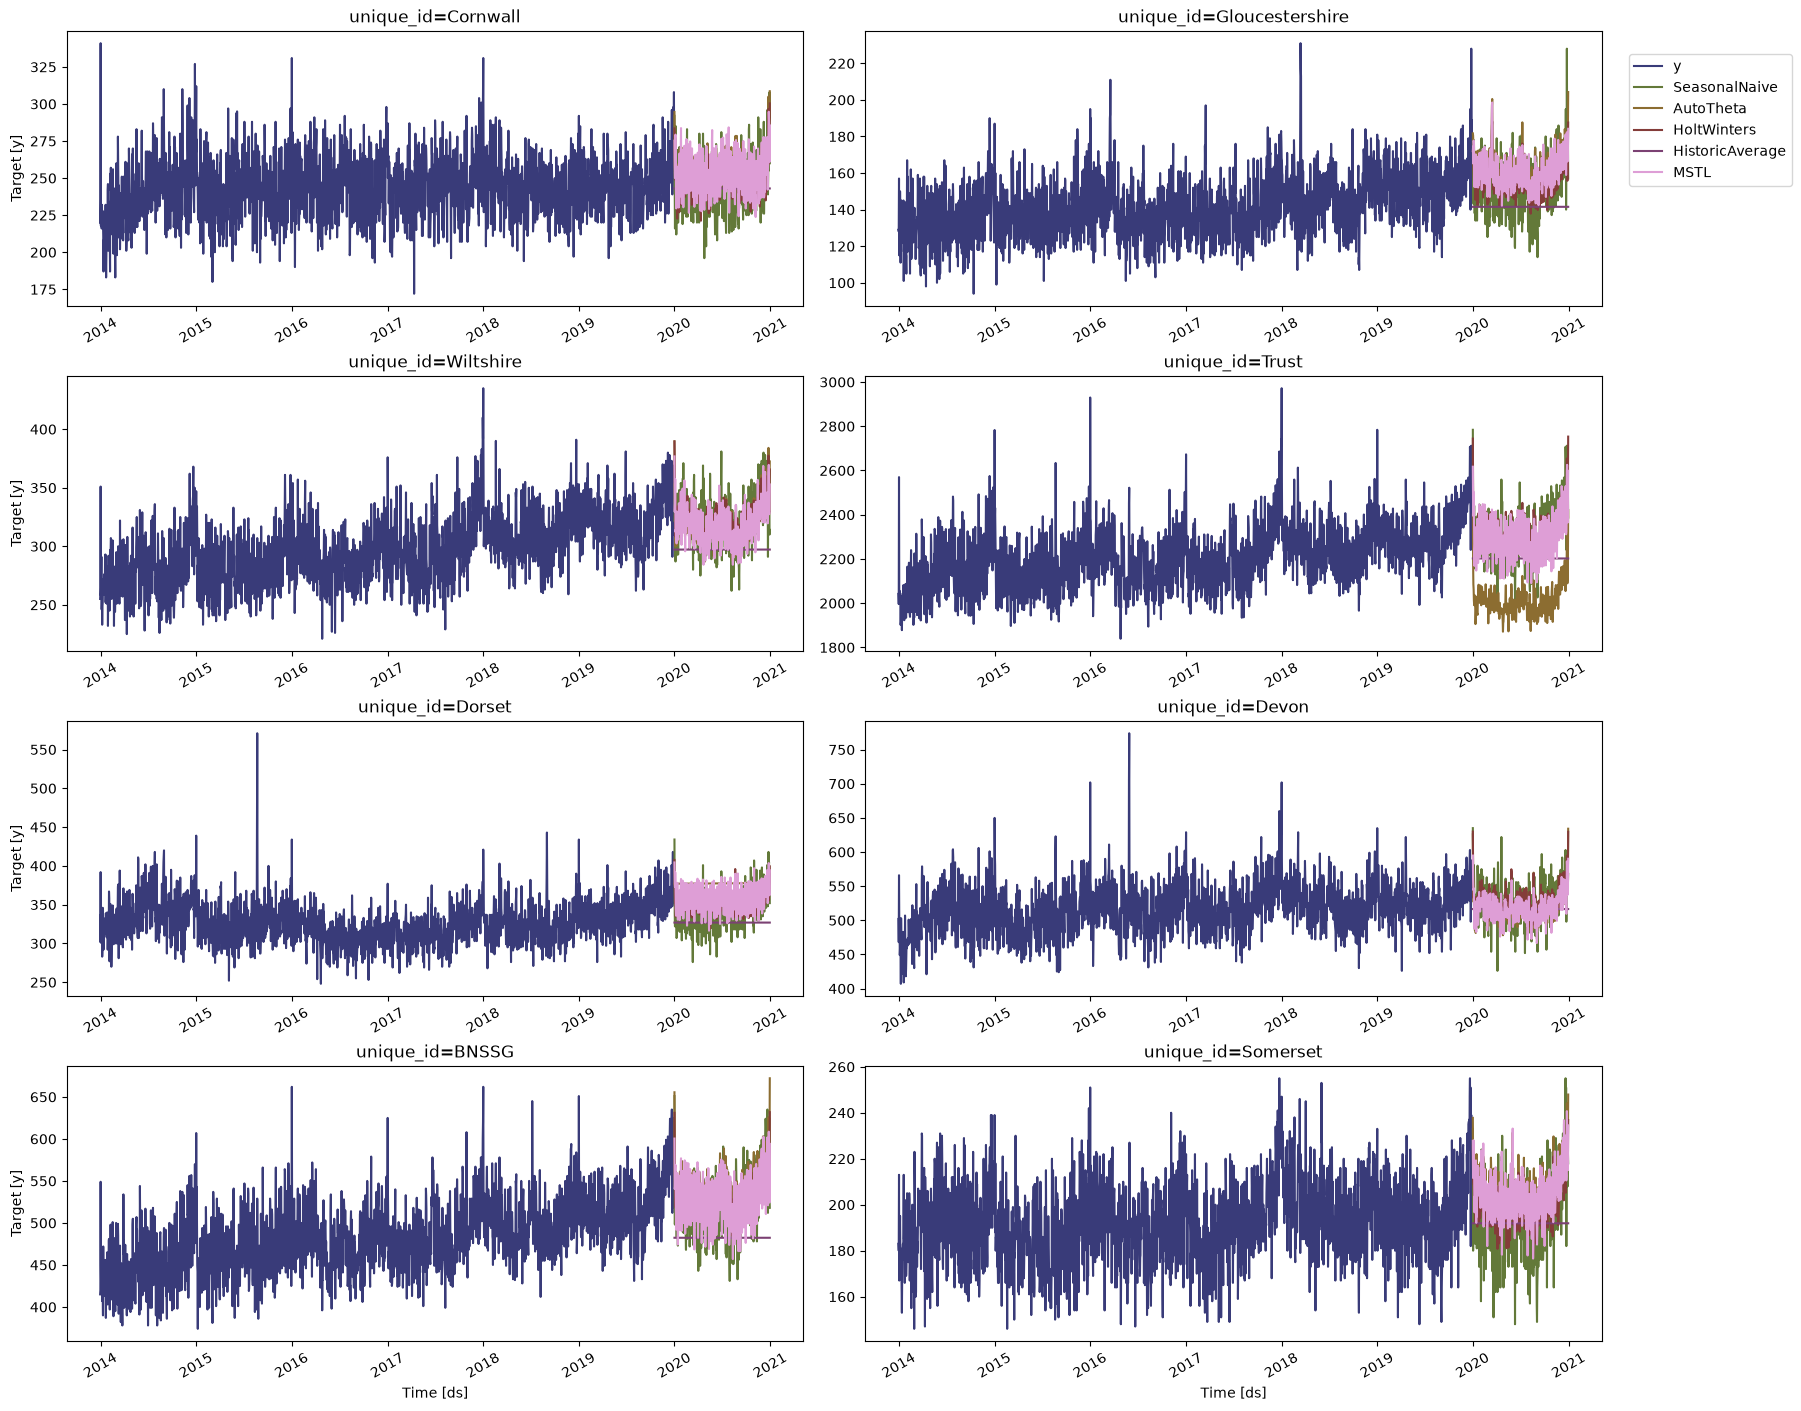

In [71]:
sf.plot(df_filtered,forecasts_df)